<a href="https://colab.research.google.com/github/Ambartheanalyst-blip/Assignment-1/blob/main/PRoject_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# An Exploration of NYC Public Schools

## 1. Project Goal
This project compares the Regents Mean Score of one selected NYC public school with other schools located in the same borough to analyze academic performance differences using descriptive statistics and visualization.

## 2. Import Libraries

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

## 3. Load the Dataset

In [22]:
url = "https://raw.githubusercontent.com/CunyLaguardiaDataAnalytics/datasets/master/2014-15_To_2016-17_School-_Level_NYC_Regents_Report_For_All_Variables.csv"
df = pd.read_csv(url)
df.head()

,School DBN,School Name,School Level,Regents Exam,Year,Total Tested,Mean Score,Number Scoring Below 65,Percent Scoring Below 65,Number Scoring 65 or Above,Percent Scoring 65 or Above,Number Scoring 80 or Above,Percent Scoring 80 or Above,Number Scoring CR,Percent Scoring CR
0,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Common Core Algebra,2017,4,s,s,s,s,s,s,s,na,na
1,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Living Environment,2015,16,77.9,1,6.3,15,93.8,7,43.8,na,na
2,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Living Environment,2016,9,74,1,11.1,8,88.9,2,22.2,na,na
3,01M140,P.S. 140 Nathan Straus,K-8,Common Core Algebra,2016,3,s,s,s,s,s,s,s,na,na
4,01M140,P.S. 140 Nathan Straus,K-8,Common Core Algebra,2017,2,s,s,s,s,s,s,s,na,na


## 4. Inspect the Dataset

In [23]:
display(df.head())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()

,School DBN,School Name,School Level,Regents Exam,Year,Total Tested,Mean Score,Number Scoring Below 65,Percent Scoring Below 65,Number Scoring 65 or Above,Percent Scoring 65 or Above,Number Scoring 80 or Above,Percent Scoring 80 or Above,Number Scoring CR,Percent Scoring CR
0,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Common Core Algebra,2017,4,s,s,s,s,s,s,s,na,na
1,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Living Environment,2015,16,77.9,1,6.3,15,93.8,7,43.8,na,na
2,01M034,P.S. 034 Franklin D. Roosevelt,K-8,Living Environment,2016,9,74,1,11.1,8,88.9,2,22.2,na,na
3,01M140,P.S. 140 Nathan Straus,K-8,Common Core Algebra,2016,3,s,s,s,s,s,s,s,na,na
4,01M140,P.S. 140 Nathan Straus,K-8,Common Core Algebra,2017,2,s,s,s,s,s,s,s,na,na


Number of rows: 212331
Number of columns: 15
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212331 entries, 0 to 212330
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   School DBN                   212331 non-null  object
 1   School Name                  212331 non-null  object
 2   School Level                 212331 non-null  object
 3   Regents Exam                 212321 non-null  object
 4   Year                         212331 non-null  int64 
 5   Total Tested                 212331 non-null  int64 
 6   Mean Score                   212331 non-null  object
 7   Number Scoring Below 65      212331 non-null  object
 8   Percent Scoring Below 65     212331 non-null  object
 9   Number Scoring 65 or Above   212331 non-null  object
 10  Percent Scoring 65 or Above  212331 non-null  object
 11  Number Scoring 80 or Above   212331 non-null  object
 12  Percent Scoring 80 or Above

## 5. Select Relevant Columns

In [24]:
# Map the 3rd character of the School DBN to the borough name
borough_map = {'M': 'Manhattan', 'X': 'Bronx', 'K': 'Brooklyn', 'Q': 'Queens', 'R': 'Staten Island'}
df['Borough'] = df['School DBN'].str[2].map(borough_map)

# Retain columns for School Name, Borough, and Mean Score
school_df = df[['School Name', 'Borough', 'Mean Score']].copy()
school_df.head()

,School Name,Borough,Mean Score
0,P.S. 034 Franklin D. Roosevelt,Manhattan,s
1,P.S. 034 Franklin D. Roosevelt,Manhattan,77.9
2,P.S. 034 Franklin D. Roosevelt,Manhattan,74
3,P.S. 140 Nathan Straus,Manhattan,s
4,P.S. 140 Nathan Straus,Manhattan,s


## 6. Clean the Data

In [25]:
rows_before = len(school_df)

# Convert Mean Score to numeric, turning invalid/suppressed values (like 's') into NaN
school_df['Mean Score'] = pd.to_numeric(school_df['Mean Score'], errors='coerce')

# Remove records missing School Name, Borough, or Mean Score
school_df = school_df.dropna(subset=['School Name', 'Borough', 'Mean Score'])

rows_after = len(school_df)
rows_removed = rows_before - rows_after

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning: {rows_after}")
print(f"Rows removed: {rows_removed}")

Rows before cleaning: 212331
Rows after cleaning: 137109
Rows removed: 75222


## 7. Select One School

In [26]:
# Choose a school with valid records
selected_school = school_df['School Name'].iloc[0]
print("Selected School:", selected_school)

# Identify and store the school's borough
selected_borough = school_df.loc[school_df['School Name'] == selected_school, 'Borough'].iloc[0]
print("Selected Borough:", selected_borough)

Selected School: P.S. 034 Franklin D. Roosevelt
Selected Borough: Manhattan


## 8. Create the Comparison

In [27]:
# Filter data for the selected school
selected_school_data = school_df[school_df['School Name'] == selected_school]

# Filter comparison data for other schools in the same borough (excluding the selected school)
comparison_data = school_df[(school_df['Borough'] == selected_borough) & (school_df['School Name'] != selected_school)]

## 9. Descriptive Statistics

In [28]:
# Calculate descriptive statistics for the selected school
selected_stats = {
    'Count': selected_school_data['Mean Score'].count(),
    'Mean': round(selected_school_data['Mean Score'].mean(), 2),
    'Median': round(selected_school_data['Mean Score'].median(), 2),
    'Minimum': round(selected_school_data['Mean Score'].min(), 2),
    'Maximum': round(selected_school_data['Mean Score'].max(), 2)
}

# Calculate descriptive statistics for the comparison group
comparison_stats = {
    'Count': comparison_data['Mean Score'].count(),
    'Mean': round(comparison_data['Mean Score'].mean(), 2),
    'Median': round(comparison_data['Mean Score'].median(), 2),
    'Minimum': round(comparison_data['Mean Score'].min(), 2),
    'Maximum': round(comparison_data['Mean Score'].max(), 2)
}

# Combine into a comparison table
stats_table = pd.DataFrame([selected_stats, comparison_stats], index=[selected_school, f"Other schools in {selected_borough}"])
display(stats_table)

,Count,Mean,Median,Minimum,Maximum
P.S. 034 Franklin D. Roosevelt,10,76.75,77.9,73.5,80.0
Other schools in Manhattan,31194,67.82,67.3,24.9,98.3


## 10. Visualization

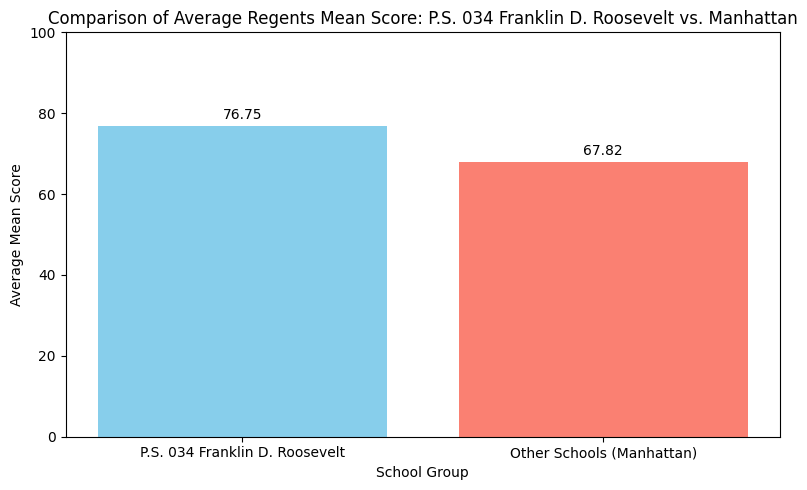

In [29]:
# Calculate average mean scores for the bar chart
avg_selected = selected_stats['Mean']
avg_comparison = comparison_stats['Mean']

# Create a bar chart comparing average Mean Scores
plt.figure(figsize=(8, 5))
bars = plt.bar([selected_school, f"Other Schools ({selected_borough})"], [avg_selected, avg_comparison], color=['skyblue', 'salmon'])

plt.title(f"Comparison of Average Regents Mean Score: {selected_school} vs. {selected_borough}")
plt.xlabel("School Group")
plt.ylabel("Average Mean Score")
plt.ylim(0, 100)

# Display the mean value above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 1, f"{height:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

## 11. Explain the Visualization

The bar chart provides a descriptive comparison of the average Regents Mean Score between the selected school and other schools in the same borough. Depending on the calculated averages, one group achieved a higher average score than the other.

## 12. Conclusion

In [30]:
# Print an in-depth conclusion using actual calculated values
conclusion_text = (
    f"Conclusion: This descriptive analysis shows that {selected_school} achieved an average Regents Mean Score of {avg_selected:.2f}, "
    f"which is higher than the average of {avg_comparison:.2f} observed across other schools in {selected_borough}. "
    f"While this indicates a descriptive performance difference during the 2014-15 to 2016-17 period, "
    f"it does not imply a causal relationship or explain the underlying factors behind this variation."
)
print(conclusion_text)

Conclusion: This descriptive analysis shows that P.S. 034 Franklin D. Roosevelt achieved an average Regents Mean Score of 76.75, which is higher than the average of 67.82 observed across other schools in Manhattan. While this indicates a descriptive performance difference during the 2014-15 to 2016-17 period, it does not imply a causal relationship or explain the underlying factors behind this variation.


## 13. Dataset Reference
Dataset: 2014-15 to 2016-17 School-Level NYC Regents Report for All Variables  
Source: https://raw.githubusercontent.com/CunyLaguardiaDataAnalytics/datasets/master/2014-15_To_2016-17_School-_Level_NYC_Regents_Report_For_All_Variables.csv